# Controlled scalar graph-input normalization
Fit one positive RMS scale using only the 193 graph-available training users' three raw degree channels. Divide all observed node features by that same scale, independently within each permitted graph. Preserve raw artifacts, topology, masks, Phase-2 tabular features, model architecture and all training settings.
Compare six new scaled runs against frozen raw MLP/GCN controls and the temporal reference. No test scoring, threshold tuning, log compression, centering, learned normalization, new activation or added fusion component.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/graph_scaling_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.graph_scaling import run, verify
import pandas as pd
output_dir = ROOT / 'results/versions/graph_scaling_v1/20260922T052601567701Z_4a1137a7'
metrics_table = pd.read_csv(output_dir / 'validation_metrics.csv')
seed_summary = pd.read_csv(output_dir / 'seed_summary.csv')
print('OUTPUT_VERSION:', output_dir)
verification = verify(ROOT, output_dir)
print(verification)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\graph_scaling_v1\20260922T052601567701Z_4a1137a7


{'new_training_runs': 6, 'scaled_checkpoints_reloaded': 12, 'frozen_checkpoints_reloaded': 18, 'validation_prediction_files': 30, 'keyed_diagnostic_files': 60, 'test_inputs_parsed': 0, 'fit_users': 193, 'scalar': 454.3006810563794, 'protected_files_at_execution': 942}


## Matched comparisons
Seeds 42/43/44; 50 epochs; identical initial weights and actual minibatch orders to the raw controls; fixed loss, optimizer and threshold 0.5. Save earliest minimum unweighted validation-BCE and final-epoch checkpoints. All 144 validation users are retained, with matched 42 graph-covered and 102 graph-unavailable cohorts. No automatic promotion.

,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std
0,degree_mlp,best_unweighted_validation_loss,all,0.387752,0.058232,0.301241,0.052361,0.547619,0.074345,0.688424,0.052207,0.372620,0.110236,0.208292,0.016544
1,degree_mlp,best_unweighted_validation_loss,graph_available,0.273810,0.286457,0.523810,0.501698,0.238095,0.297381,0.903401,0.049206,0.757078,0.056333,0.142234,0.017034
2,degree_mlp,best_unweighted_validation_loss,graph_unavailable,0.394263,0.027723,0.284818,0.035330,0.650794,0.054986,0.677445,0.050900,0.394443,0.122270,0.235493,0.017265
6,gcn,best_unweighted_validation_loss,all,0.428347,0.091277,0.331853,0.078713,0.607143,0.107143,0.715517,0.076709,0.435573,0.137921,0.194469,0.014414
7,gcn,best_unweighted_validation_loss,graph_available,0.386111,0.337509,0.351852,0.305976,0.428571,0.377964,0.889796,0.057579,0.748473,0.099976,0.123760,0.004830
8,gcn,best_unweighted_validation_loss,graph_unavailable,0.421286,0.059576,0.310774,0.060192,0.666667,0.047619,0.697433,0.063015,0.444712,0.133437,0.223585,0.018790
12,scaled_degree_mlp,best_unweighted_validation_loss,all,0.439843,0.035874,0.345914,0.032647,0.607143,0.061859,0.763239,0.009086,0.545974,0.013179,0.187937,0.007079
13,scaled_degree_mlp,best_unweighted_validation_loss,graph_available,0.519761,0.055238,0.496032,0.077457,0.571429,0.142857,0.840816,0.021598,0.675433,0.022645,0.120309,0.007272
14,scaled_degree_mlp,best_unweighted_validation_loss,graph_unavailable,0.419672,0.034073,0.317716,0.028621,0.619048,0.047619,0.729571,0.013560,0.522884,0.021586,0.215783,0.007240
18,scaled_gcn,best_unweighted_validation_loss,all,0.431427,0.036602,0.339141,0.033336,0.595238,0.054554,0.762418,0.010852,0.531423,0.004064,0.188248,0.007005


,comparison,seed,policy,cohort,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier
0,scaled_gcn_minus_gcn,42,best_unweighted_validation_loss,all,0.084057,0.067712,0.107143,0.132389,0.250227,-0.014681
6,scaled_gcn_minus_gcn,43,best_unweighted_validation_loss,all,-0.026316,-0.009615,-0.071429,0.006466,0.026348,-0.003270
12,scaled_gcn_minus_gcn,44,best_unweighted_validation_loss,all,-0.048501,-0.036232,-0.071429,0.001847,0.010974,-0.000713
18,scaled_degree_mlp_minus_degree_mlp,42,best_unweighted_validation_loss,all,0.060755,0.050242,0.071429,0.065271,0.203545,-0.030167
24,scaled_degree_mlp_minus_degree_mlp,43,best_unweighted_validation_loss,all,0.137895,0.112145,0.178571,0.139778,0.272461,-0.019823
30,scaled_degree_mlp_minus_degree_mlp,44,best_unweighted_validation_loss,all,-0.042374,-0.028369,-0.071429,0.019397,0.044058,-0.011077
36,scaled_gcn_minus_scaled_degree_mlp,42,best_unweighted_validation_loss,all,-0.018933,-0.012338,-0.035714,0.001232,-0.008905,0.000151
42,scaled_gcn_minus_scaled_degree_mlp,43,best_unweighted_validation_loss,all,-0.006316,-0.007979,0.000000,0.000616,-0.026601,0.000603
48,scaled_gcn_minus_scaled_degree_mlp,44,best_unweighted_validation_loss,all,0.000000,0.000000,0.000000,-0.004310,-0.008149,0.000179
54,scaled_gcn_minus_temporal_anchor,42,best_unweighted_validation_loss,all,-0.057894,-0.058256,-0.035714,-0.013547,-0.007919,0.006933


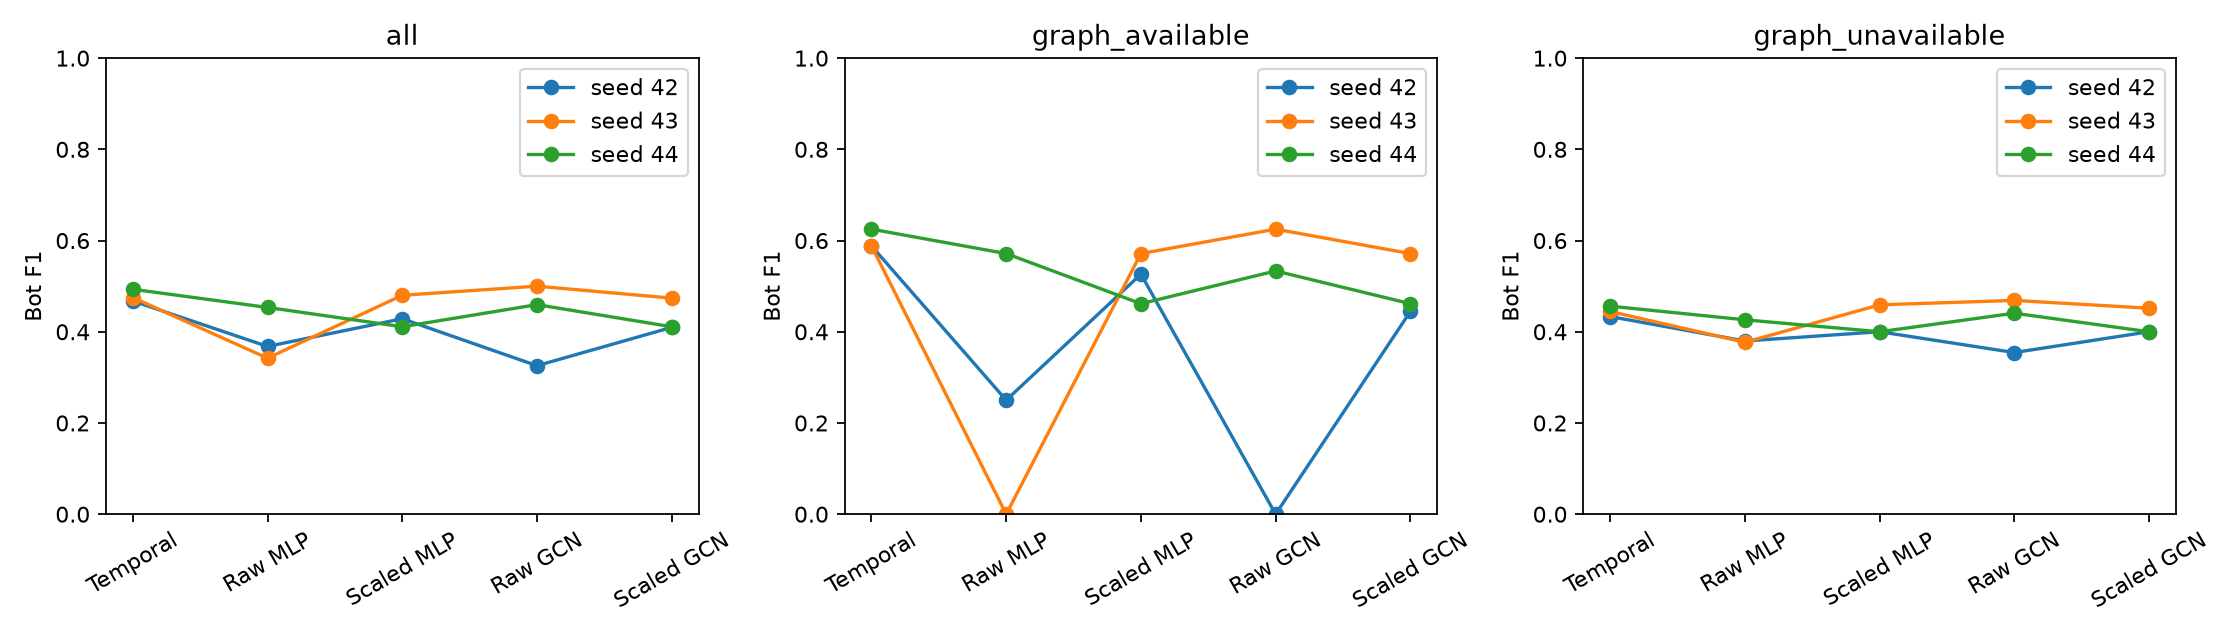

In [2]:
import pandas as pd
from IPython.display import Image, display
display(seed_summary[seed_summary.policy.eq('best_unweighted_validation_loss')])
effects = pd.read_csv(output_dir / 'paired_effects.csv')
display(effects[effects.policy.eq('best_unweighted_validation_loss') & effects.cohort.eq('all')])
display(Image(filename=str(output_dir / 'figures/paired_f1.png')))

In [3]:
branches = pd.read_csv(output_dir / 'branch_diagnostics.csv')
display(branches[branches.split.eq('validation')])
display(pd.read_csv(output_dir / 'graph_coverage.csv'))

,arm,seed,policy,epoch,split,covered_users,graph_zero_vectors,graph_rms_median,graph_effect_median,weighted_graph_ratio_median
1,temporal_anchor,42,best_unweighted_validation_loss,12,validation,42,NaN,NaN,NaN,NaN
3,temporal_anchor,42,last,50,validation,42,NaN,NaN,NaN,NaN
5,degree_mlp,42,best_unweighted_validation_loss,5,validation,42,0.0,37.724556,-0.342503,26.017009
7,degree_mlp,42,last,50,validation,42,0.0,57.974859,1.299124,29.272297
9,gcn,42,best_unweighted_validation_loss,2,validation,42,0.0,26.717443,-1.165486,24.217894
11,gcn,42,last,50,validation,42,0.0,4.211811,0.428081,2.182756
13,temporal_anchor,43,best_unweighted_validation_loss,21,validation,42,NaN,NaN,NaN,NaN
15,temporal_anchor,43,last,50,validation,42,NaN,NaN,NaN,NaN
17,degree_mlp,43,best_unweighted_validation_loss,2,validation,42,0.0,45.353254,-1.026580,51.943964
19,degree_mlp,43,last,50,validation,42,0.0,25.008932,0.634115,7.494844


,split,canonical_users,graph_available,graph_unavailable,graph_nodes,observed_directed_edges,eligible_bots,forbidden_gold_endpoints
0,train,671,193,478,42954,60924,31,0
1,validation,144,42,102,11436,13006,7,0


## Limits
Only graph input magnitude changes; scaling can affect optimization and effective regularization despite identical model capacity. Three seeds measure limited optimization variability, not population uncertainty. Validation is reused for development and checkpoint selection. Graph-covered validation contains seven bots. See reports/GRAPH_INPUT_SCALING_EXPERIMENT.md for results and interpretation. Raw checkpoints and every earlier experiment remain frozen.